# Notebook 01 — Market Data Pipeline

Every quantitative risk model starts with reliable market data. In this notebook, daily adjusted closing prices are downloaded for five large-cap U.S. companies over a ten-year period.

The adjusted prices are then converted into daily log returns, which are commonly used in quantitative finance because they are additive over time and suitable for risk modelling. The processed datasets created here serve as the foundation for every notebook in this project.

**Portfolio**
AAPL • JPM • XOM • JNJ • GS

**Period**
January 2015 – December 2024

## Outputs

- `raw_prices.csv`
- `log_returns.csv`
- Cumulative performance visualization


Loaded: 2515 trading days × 5 tickers
Period: 2015-01-02 to 2024-12-30
Ticker         AAPL       GS      JNJ      JPM      XOM
Date                                                   
2024-12-26 257.3756 564.1371 139.7056 234.7660 101.3520
2024-12-27 253.9674 559.2358 139.1970 232.8639 101.3425
2024-12-30 250.5989 556.6830 137.5560 231.0776 100.6572

Returns
Ticker      AAPL        GS       JNJ       JPM       XOM
count  2514.0000 2514.0000 2514.0000 2514.0000 2514.0000
mean      0.0009    0.0005    0.0002    0.0006    0.0002
std       0.0179    0.0182    0.0114    0.0172    0.0175
min      -0.1377   -0.1359   -0.1058   -0.1621   -0.1304
25%      -0.0074   -0.0084   -0.0050   -0.0072   -0.0083
50%       0.0010    0.0004    0.0003    0.0006    0.0002
75%       0.0101    0.0101    0.0059    0.0087    0.0088
max       0.1132    0.1620    0.0769    0.1656    0.1194


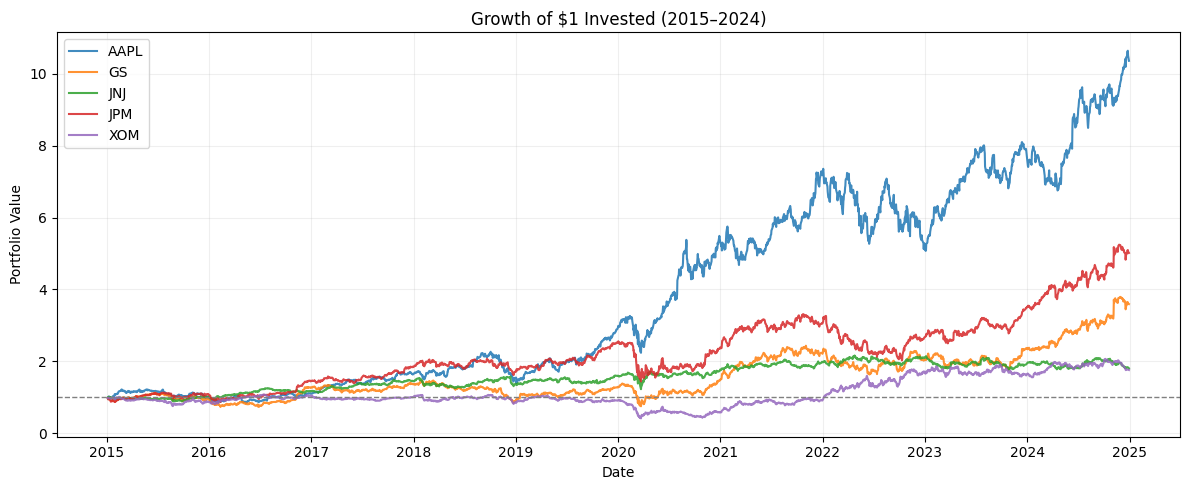


raw_prices.csv  → (2515, 5)
log_returns.csv → (2514, 5)


In [ ]:
# Data: Yahoo Finance via yfinance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
import os


pd.set_option('display.float_format', '{:.4f}'.format)

# Portfolio definition
TICKERS = ['AAPL', 'JPM', 'XOM', 'JNJ', 'GS']
start_date = '2015-01-01'
end_date  = '2024-12-31'
weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

assert np.isclose(weights.sum(), 1.0)

# Download adjusted closing prices
raw_data = yf.download(
    tickers = TICKERS,
    start = start_date,
    end = end_date,
    auto_adjust = True,
    progress  = False)

prices = raw_data['Close']

assert prices.isnull().sum().sum() == 0, "Missing values in price data"

print(f"Loaded: {prices.shape[0]} trading days × {prices.shape[1]} tickers")
print(f"Period: {prices.index[0].date()} to {prices.index[-1].date()}")
print(prices.tail(3))

# Log returns 
log_returns = np.log(prices / prices.shift(1)).dropna()

print(f"\nReturns")
print(log_returns.describe())

#  Cumulative Performance 

fig, ax = plt.subplots(figsize=(12, 5))
cumulative = np.exp(log_returns.cumsum())

for ticker in cumulative.columns:
    ax.plot(
        cumulative.index,
        cumulative[ticker],
        label=ticker,
        linewidth=1.5,
         alpha=0.85)
ax.axhline(y=1, color='gray', linestyle='--', linewidth=1)

# Chart title and axis labels
ax.set_title('Growth of $1 Invested (2015–2024)')
ax.set_xlabel('Date')
ax.set_ylabel('Portfolio Value')


ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()

os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/01_cumulative_performance.png', dpi=150)
plt.show()

# Save processed datasets for later notebooks
os.makedirs('../data', exist_ok=True)
prices.to_csv('../data/raw_prices.csv')
log_returns.to_csv('../data/log_returns.csv')

print(f"\nraw_prices.csv  → {prices.shape}")
print(f"log_returns.csv → {log_returns.shape}")